# Análisis comparativo final: Rspamd vs. LLM+MCP (veredicto) vs. LLM+MCP (explicación) sobre 1,000 correos

Compara los tres sistemas sobre el conjunto de evaluación externo completo, `eval_external.csv`
(500 phishing de Phishing Pot + 500 legítimos de TREC 2007). Es la versión final de
`analisis_comparativo_100.ipynb` y `analisis_comparativo_200.ipynb`: ahora los tres sistemas están evaluados
sobre los mismos 1,000 correos.

- **Rspamd**: filtro basado en reglas (`rspamd_results_raw.jsonl`).
- **LLM+MCP, modo veredicto**: orquestador con los servidores archetype + virustotal (`data/results_raw.jsonl`).
- **LLM+MCP, modo explicación**: orquestador con los cuatro servidores MCP (`results_explicacion_1000.jsonl`).

## 1. Imports y carga de datos

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.stats import binomtest
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    accuracy_score,
    confusion_matrix,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)

RANDOM_STATE = 42
plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams.update({"figure.dpi": 150, "savefig.dpi": 150, "savefig.bbox": "tight"})

# Carpeta experiments/ (funciona si el notebook se ejecuta desde experiments/ o desde la raíz del repo)
BASE = Path.cwd() if (Path.cwd() / "eval_system").exists() else Path.cwd() / "experiments"

RUTA_CSV = BASE / "external_eval" / "eval_external.csv"
RUTA_RSPAMD = BASE / "eval_system" / "rspamd_results_raw.jsonl"
RUTA_EXPLICACION = BASE / "eval_system" / "results_explicacion_1000.jsonl"
# results_raw.jsonl (modo veredicto) puede estar en experiments/data/ o en data/ (raíz del repo)
RUTAS_VEREDICTO = [BASE.parent / "data" / "results_raw_veredicto.jsonl", BASE / "data" / "results_raw.jsonl", BASE.parent / "data" / "results_raw.jsonl"]
RUTA_VEREDICTO = next((p for p in RUTAS_VEREDICTO if p.exists()), RUTAS_VEREDICTO[0])

FIGURES_DIR = BASE / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

RSPAMD_SCORE_TOPE = 20.0  # divisor para normalizar el score crudo de Rspamd a [0, 1]

# Nombre y color de cada sistema (se reutiliza en todas las secciones)
SISTEMAS = {
    "rspamd": {"nombre": "Rspamd", "color": "tab:orange"},
    "veredicto": {"nombre": "LLM+MCP (veredicto)", "color": "tab:blue"},
    "explicacion": {"nombre": "LLM+MCP (explicación)", "color": "tab:green"},
}
# Umbrales objetivo de la tesis
OBJETIVOS = {"Recall": 0.85, "F1": 0.82, "AUC-ROC": 0.88, "MCC": 0.70}


def cargar_jsonl(ruta: Path) -> pd.DataFrame:
    with ruta.open(encoding="utf-8") as f:
        return pd.DataFrame([json.loads(linea) for linea in f if linea.strip()])

In [2]:
# Los 1,000 correos de referencia: id es la llave, label la etiqueta real
correos = pd.read_csv(RUTA_CSV, usecols=["id", "label", "source"])
ids_ref = set(correos["id"])

rspamd = cargar_jsonl(RUTA_RSPAMD)
veredicto = cargar_jsonl(RUTA_VEREDICTO)
explicacion = cargar_jsonl(RUTA_EXPLICACION)

# Advertencia (sin fallar) si algún correo no aparece en un archivo de resultados, o aparece repetido
for nombre, tabla in [("rspamd_results_raw.jsonl", rspamd), ("results_raw.jsonl", veredicto),
                      ("results_explicacion_1000.jsonl", explicacion)]:
    faltantes = sorted(ids_ref - set(tabla["id"]))
    repetidos = int(tabla["id"].duplicated().sum())
    con_error = int(tabla.loc[tabla["id"].isin(ids_ref), "error"].notna().sum())
    if faltantes:
        print(f"ADVERTENCIA: {len(faltantes)} ids no están en {nombre}: {faltantes[:5]}{' ...' if len(faltantes) > 5 else ''}")
    if repetidos:
        print(f"ADVERTENCIA: {repetidos} ids repetidos en {nombre}; se conserva la primera aparición")
    if con_error:
        print(f"ADVERTENCIA: {con_error} correos tienen error en {nombre}")
    print(f"{nombre}: {int(tabla['id'].isin(ids_ref).sum())} de {len(ids_ref)} correos")

rspamd, veredicto, explicacion = (t.drop_duplicates("id", keep="first") for t in (rspamd, veredicto, explicacion))

# Scores normalizados a [0, 1]. Rspamd: score crudo / 20, recortado (hay scores por encima de 20).
rspamd["rspamd_score"] = (rspamd["rspamd_score"] / RSPAMD_SCORE_TOPE).clip(0, 1)
veredicto = veredicto.rename(columns={"puntaje_riesgo": "veredicto_score", "clasificacion": "veredicto_clasificacion",
                                      "tiempo_ms": "veredicto_tiempo_ms", "arquetipo_label": "arquetipo",
                                      "costo_usd": "veredicto_costo_usd"})
explicacion = explicacion.rename(columns={"puntaje_riesgo": "explicacion_score", "clasificacion": "explicacion_clasificacion",
                                          "tiempo_ms": "explicacion_tiempo_ms"})
rspamd = rspamd.rename(columns={"tiempo_ms": "rspamd_tiempo_ms"})

# Un único DataFrame, una fila por correo
df = (correos
      .merge(rspamd[["id", "rspamd_score", "rspamd_tiempo_ms"]], on="id", how="left", validate="one_to_one")
      .merge(veredicto[["id", "veredicto_score", "veredicto_clasificacion", "veredicto_tiempo_ms",
                        "veredicto_costo_usd", "arquetipo"]], on="id", how="left", validate="one_to_one")
      .merge(explicacion[["id", "explicacion_score", "explicacion_clasificacion", "explicacion_tiempo_ms",
                          "senales_count", "senales", "herramientas_invocadas"]],
             on="id", how="left", validate="one_to_one"))
df["arquetipo"] = df["arquetipo"].fillna("(sin arquetipo asignado)")

print(f"\nDataFrame combinado: {len(df)} correos | phishing: {int((df['label'] == 1).sum())} | legítimos: {int((df['label'] == 0).sum())}")

rspamd_results_raw.jsonl: 1000 de 1000 correos
results_raw.jsonl: 1000 de 1000 correos
results_explicacion_1000.jsonl: 1000 de 1000 correos

DataFrame combinado: 1000 correos | phishing: 500 | legítimos: 500


## 2. Criterio de clasificación

- **Rspamd:** score normalizado ≥ 0.3 → phishing (equivale al umbral de 6.0 sobre 20 de la acción `add header`).
- **Veredicto y explicación:** se usa la clasificación que emite el propio sistema (campo `clasificacion`), que es
  su decisión real. Coincide con el umbral de 0.5 sobre el puntaje salvo en unos pocos correos del modo
  veredicto, que se listan abajo. El puntaje se usa para las curvas ROC y el AUC.

In [3]:
UMBRALES = {"rspamd": 0.3, "veredicto": 0.5, "explicacion": 0.5}

df["rspamd_pred"] = (df["rspamd_score"] >= UMBRALES["rspamd"]).astype("Int64").where(df["rspamd_score"].notna())
for sistema in ["veredicto", "explicacion"]:
    df[f"{sistema}_pred"] = df[f"{sistema}_clasificacion"].map({"phishing": 1, "legitimo": 0}).astype("Int64")

# Correos donde la clasificación emitida no coincide con el umbral de 0.5 sobre el puntaje
for sistema in ["veredicto", "explicacion"]:
    por_umbral = (df[f"{sistema}_score"] >= UMBRALES[sistema]).astype("Int64").where(df[f"{sistema}_score"].notna())
    distintos = df[(por_umbral != df[f"{sistema}_pred"]).fillna(False)]
    print(f"{SISTEMAS[sistema]['nombre']}: {len(distintos)} correos donde la clasificación emitida no coincide con el umbral {UMBRALES[sistema]}")
    if len(distintos):
        display(distintos[["id", "label", f"{sistema}_score", f"{sistema}_clasificacion"]].reset_index(drop=True))

COLUMNAS = ["id", "label", "rspamd_score", "rspamd_pred", "veredicto_score", "veredicto_pred",
            "explicacion_score", "explicacion_pred"]
df[COLUMNAS].head(10)

LLM+MCP (veredicto): 3 correos donde la clasificación emitida no coincide con el umbral 0.5


,id,label,veredicto_score,veredicto_clasificacion
0,phishing_pot_sample-1119,1,0.35,phishing
1,phishing_pot_sample-1067,1,0.42,phishing
2,trec_2007_157,0,0.42,phishing


LLM+MCP (explicación): 0 correos donde la clasificación emitida no coincide con el umbral 0.5


,id,label,rspamd_score,rspamd_pred,veredicto_score,veredicto_pred,explicacion_score,explicacion_pred
0,trec_2007_21,0,0.2000,0,0.05,0,0.05,0
1,trec_2007_237,0,0.2000,0,0.05,0,0.02,0
2,trec_2007_240,0,0.4050,1,0.08,0,0.08,0
3,trec_2007_160,0,0.4500,1,0.15,0,0.25,0
4,phishing_pot_sample-137,1,0.4100,1,0.92,1,0.95,1
5,trec_2007_178,0,0.2500,0,0.05,0,0.05,0
6,trec_2007_126,0,0.4500,1,0.08,0,0.05,0
7,trec_2007_13,0,0.3000,1,0.08,0,0.05,0
8,trec_2007_359,0,0.5050,1,0.05,0,0.05,0
9,phishing_pot_sample-1121,1,0.5675,1,0.82,1,0.95,1


## 3. Métricas por sistema

Tabla comparativa, cumplimiento de los umbrales objetivo de la tesis e intervalos de confianza del 95 % por
bootstrap.

In [4]:
def datos_sistema(sistema: str, tabla: pd.DataFrame = None):
    """Etiquetas, predicciones y scores de un sistema, sin los correos que no tengan resultado."""
    tabla = df if tabla is None else tabla
    validos = tabla[tabla[f"{sistema}_pred"].notna()]
    return (validos["label"].to_numpy(), validos[f"{sistema}_pred"].astype(int).to_numpy(),
            validos[f"{sistema}_score"].to_numpy())


def metricas(y, pred, score) -> dict:
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {
        "Correos": len(y),
        "Accuracy": accuracy_score(y, pred),
        "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred, zero_division=0),
        "F1": f1_score(y, pred, zero_division=0),
        "MCC": matthews_corrcoef(y, pred),
        "AUC-ROC": roc_auc_score(y, score) if len(np.unique(y)) == 2 else np.nan,
        "FPR": fp / (fp + tn) if (fp + tn) else np.nan,
        "FNR": fn / (fn + tp) if (fn + tp) else np.nan,
        "TP": tp, "FP": fp, "FN": fn, "TN": tn,
    }


ENTERAS = ["Correos", "TP", "FP", "FN", "TN"]
METRICAS = ["Accuracy", "Precision", "Recall", "F1", "MCC", "AUC-ROC"]
TASAS_ERROR = ["FPR", "FNR"]

tabla_metricas = pd.DataFrame({info["nombre"]: metricas(*datos_sistema(s)) for s, info in SISTEMAS.items()}).T
tabla_metricas[ENTERAS] = tabla_metricas[ENTERAS].astype(int)

RESALTE = "color: black; font-weight: bold; background-color: #b7e4c7"
(tabla_metricas.style
    .format("{:.4f}", subset=METRICAS + TASAS_ERROR)
    .highlight_max(subset=METRICAS, props=RESALTE)
    .highlight_min(subset=TASAS_ERROR + ["FP", "FN"], props=RESALTE)
    .set_caption("Métricas sobre los 1,000 correos (verde = mejor valor de la columna)"))

,Correos,Accuracy,Precision,Recall,F1,MCC,AUC-ROC,FPR,FNR,TP,FP,FN,TN
Rspamd,1000,0.7850,0.7387,0.8820,0.8040,0.5810,0.8387,0.3120,0.1180,441,156,59,344
LLM+MCP (veredicto),1000,0.9150,0.9601,0.8660,0.9106,0.8340,0.9748,0.0360,0.1340,433,18,67,482
LLM+MCP (explicación),1000,0.9350,0.9541,0.9140,0.9336,0.8708,0.9794,0.0440,0.0860,457,22,43,478


In [5]:
# Cumplimiento de los umbrales objetivo de la tesis
cumple = pd.DataFrame({
    f"{m} ≥ {objetivo}": tabla_metricas[m].astype(float).map(lambda v, o=objetivo: f"{v:.3f} {'✓' if v >= o else '✗'}")
    for m, objetivo in OBJETIVOS.items()
})
cumple["Umbrales cumplidos"] = [
    f"{sum(float(tabla_metricas.loc[s, m]) >= o for m, o in OBJETIVOS.items())} de {len(OBJETIVOS)}" for s in tabla_metricas.index
]
cumple

,Recall ≥ 0.85,F1 ≥ 0.82,AUC-ROC ≥ 0.88,MCC ≥ 0.7,Umbrales cumplidos
Rspamd,0.882 ✓,0.804 ✗,0.839 ✗,0.581 ✗,1 de 4
LLM+MCP (veredicto),0.866 ✓,0.911 ✓,0.975 ✓,0.834 ✓,4 de 4
LLM+MCP (explicación),0.914 ✓,0.934 ✓,0.979 ✓,0.871 ✓,4 de 4


In [6]:
# Intervalos de confianza del 95 % por bootstrap (2,000 remuestreos con reemplazo de los correos)
N_BOOTSTRAP = 2000
rng = np.random.default_rng(RANDOM_STATE)

ic = {}
for sistema, info in SISTEMAS.items():
    y, pred, score = datos_sistema(sistema)
    muestras = {"Accuracy": [], "Precision": [], "Recall": [], "F1": [], "AUC-ROC": []}
    for _ in range(N_BOOTSTRAP):
        idx = rng.integers(0, len(y), len(y))
        if len(np.unique(y[idx])) < 2:  # el AUC necesita ambas clases
            continue
        muestras["Accuracy"].append(accuracy_score(y[idx], pred[idx]))
        muestras["Precision"].append(precision_score(y[idx], pred[idx], zero_division=0))
        muestras["Recall"].append(recall_score(y[idx], pred[idx], zero_division=0))
        muestras["F1"].append(f1_score(y[idx], pred[idx], zero_division=0))
        muestras["AUC-ROC"].append(roc_auc_score(y[idx], score[idx]))
    ic[info["nombre"]] = {m: f"{np.percentile(v, 2.5):.3f} – {np.percentile(v, 97.5):.3f}" for m, v in muestras.items()}

pd.DataFrame(ic).T.rename(columns=lambda c: f"{c} (IC 95 %)")

,Accuracy (IC 95 %),Precision (IC 95 %),Recall (IC 95 %),F1 (IC 95 %),AUC-ROC (IC 95 %)
Rspamd,0.758 – 0.810,0.703 – 0.774,0.852 – 0.908,0.777 – 0.829,0.813 – 0.864
LLM+MCP (veredicto),0.897 – 0.932,0.941 – 0.977,0.835 – 0.897,0.891 – 0.929,0.966 – 0.983
LLM+MCP (explicación),0.919 – 0.950,0.935 – 0.972,0.887 – 0.938,0.916 – 0.950,0.971 – 0.986


## 4. Matrices de confusión

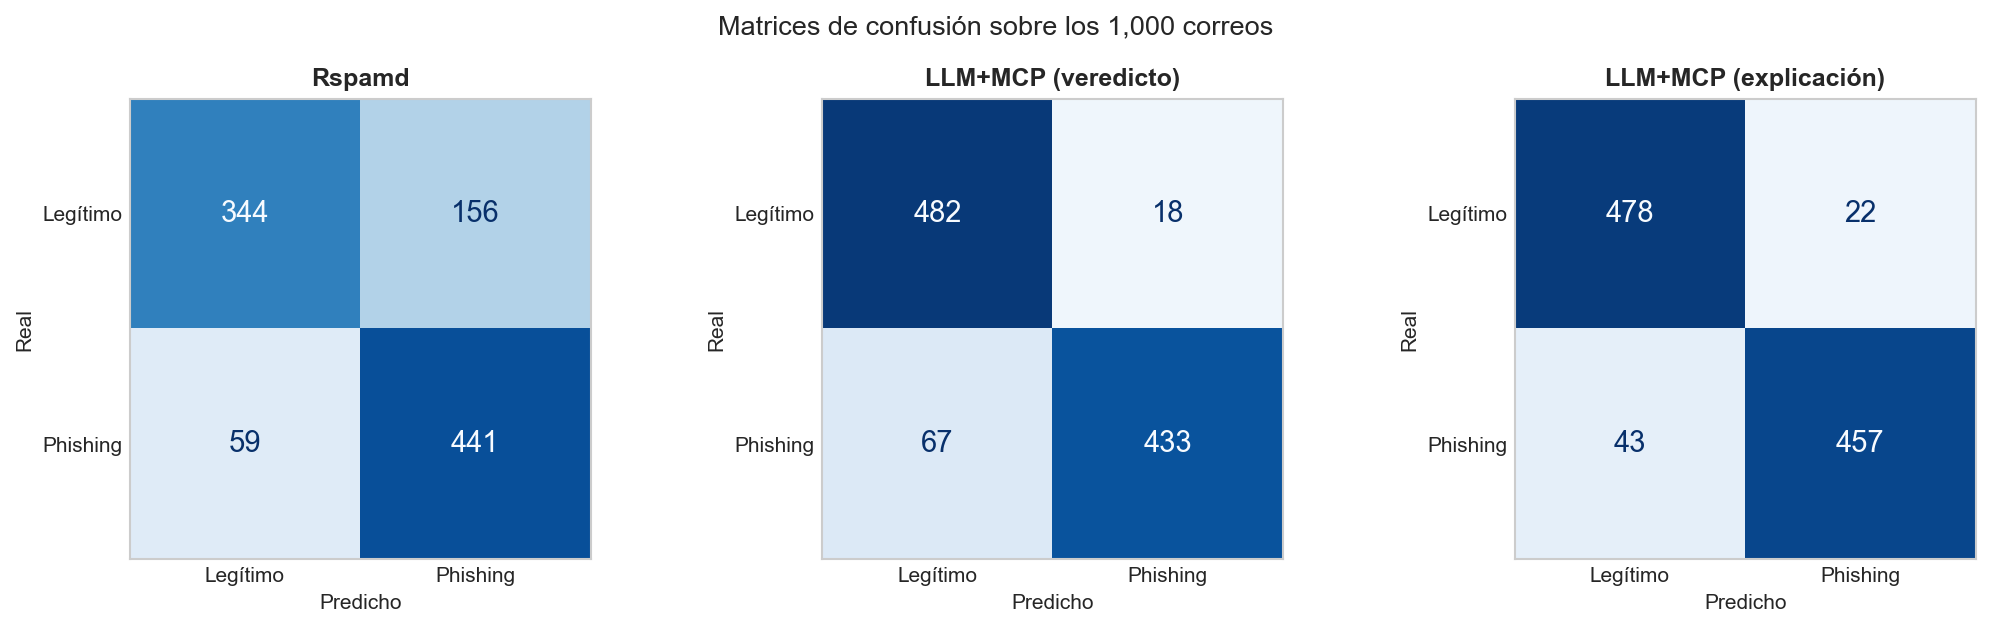

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))

for ax, (sistema, info) in zip(axes, SISTEMAS.items()):
    y, pred, _ = datos_sistema(sistema)
    ConfusionMatrixDisplay.from_predictions(
        y, pred, labels=[0, 1], display_labels=["Legítimo", "Phishing"],
        cmap="Blues", colorbar=False, ax=ax, text_kw={"fontsize": 14},
        im_kw={"vmin": 0, "vmax": 500},
    )
    ax.set_title(info["nombre"], fontweight="bold")
    ax.set_xlabel("Predicho")
    ax.set_ylabel("Real")
    ax.grid(False)

fig.suptitle("Matrices de confusión sobre los 1,000 correos", fontsize=13)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "confusion_matrices_final.png")
plt.show()

## 5. Tasas de falsos positivos y falsos negativos

- **FPR** = FP / (FP + TN): legítimos marcados como phishing (falsas alarmas).
- **FNR** = FN / (FN + TP): phishing que pasa como legítimo (el error más peligroso).

,FPR,FNR,FP,FN
Rspamd,0.312,0.118,156,59
LLM+MCP (veredicto),0.036,0.134,18,67
LLM+MCP (explicación),0.044,0.086,22,43


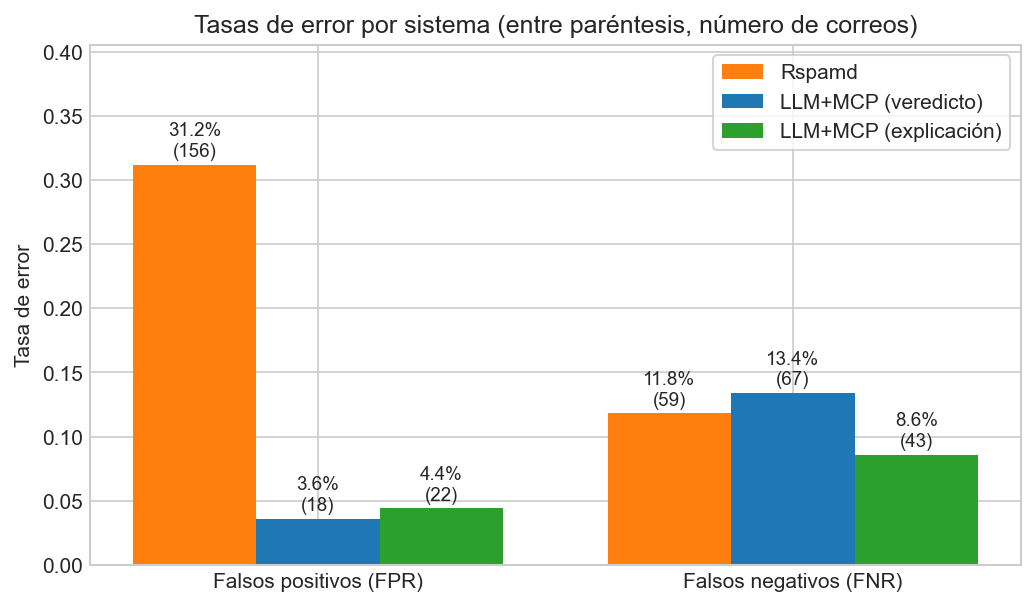

In [8]:
tasas = tabla_metricas[["FPR", "FNR", "FP", "FN"]]
display(tasas.style.format("{:.3f}", subset=["FPR", "FNR"]))

fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(2)
ancho = 0.26
for k, (sistema, info) in enumerate(SISTEMAS.items()):
    valores = tasas.loc[info["nombre"], ["FPR", "FNR"]].astype(float).to_numpy()
    conteos = tasas.loc[info["nombre"], ["FP", "FN"]].to_numpy()
    barras = ax.bar(x + (k - 1) * ancho, valores, ancho, color=info["color"], label=info["nombre"])
    ax.bar_label(barras, labels=[f"{v:.1%}\n({int(c)})" for v, c in zip(valores, conteos)], padding=2, fontsize=9)

ax.set_xticks(x)
ax.set_xticklabels(["Falsos positivos (FPR)", "Falsos negativos (FNR)"])
ax.set_ylabel("Tasa de error")
ax.set_ylim(0, tasas[["FPR", "FNR"]].to_numpy().astype(float).max() * 1.3)
ax.set_title("Tasas de error por sistema (entre paréntesis, número de correos)")
ax.legend(frameon=True)
fig.savefig(FIGURES_DIR / "error_rates_final.png")
plt.show()

## 6. Curvas ROC

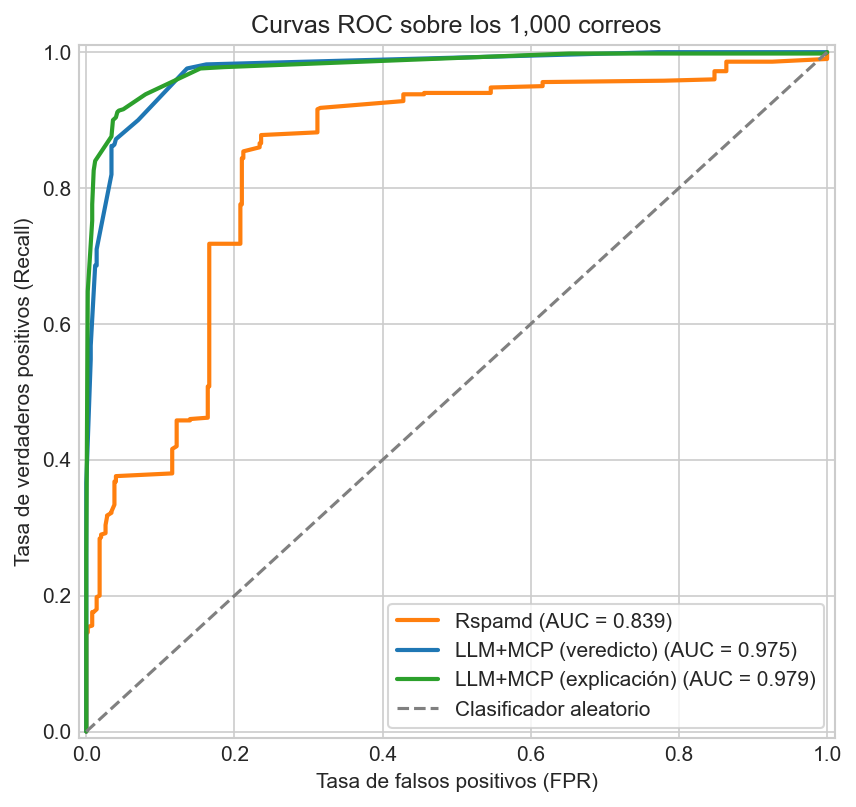

In [9]:
fig, ax = plt.subplots(figsize=(6.5, 6))

for sistema, info in SISTEMAS.items():
    y, _, score = datos_sistema(sistema)
    fpr, tpr, _ = roc_curve(y, score)
    ax.plot(fpr, tpr, color=info["color"], linewidth=2, label=f"{info['nombre']} (AUC = {roc_auc_score(y, score):.3f})")

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Clasificador aleatorio")
ax.set_xlabel("Tasa de falsos positivos (FPR)")
ax.set_ylabel("Tasa de verdaderos positivos (Recall)")
ax.set_title("Curvas ROC sobre los 1,000 correos")
ax.set_xlim(-0.01, 1.01)
ax.set_ylim(-0.01, 1.01)
ax.legend(loc="lower right", frameon=True)
fig.savefig(FIGURES_DIR / "roc_curves_final.png")
plt.show()

## 7. Distribución de scores

Cómo reparte cada sistema sus puntajes entre correos legítimos y phishing. La línea punteada es el umbral de
clasificación.

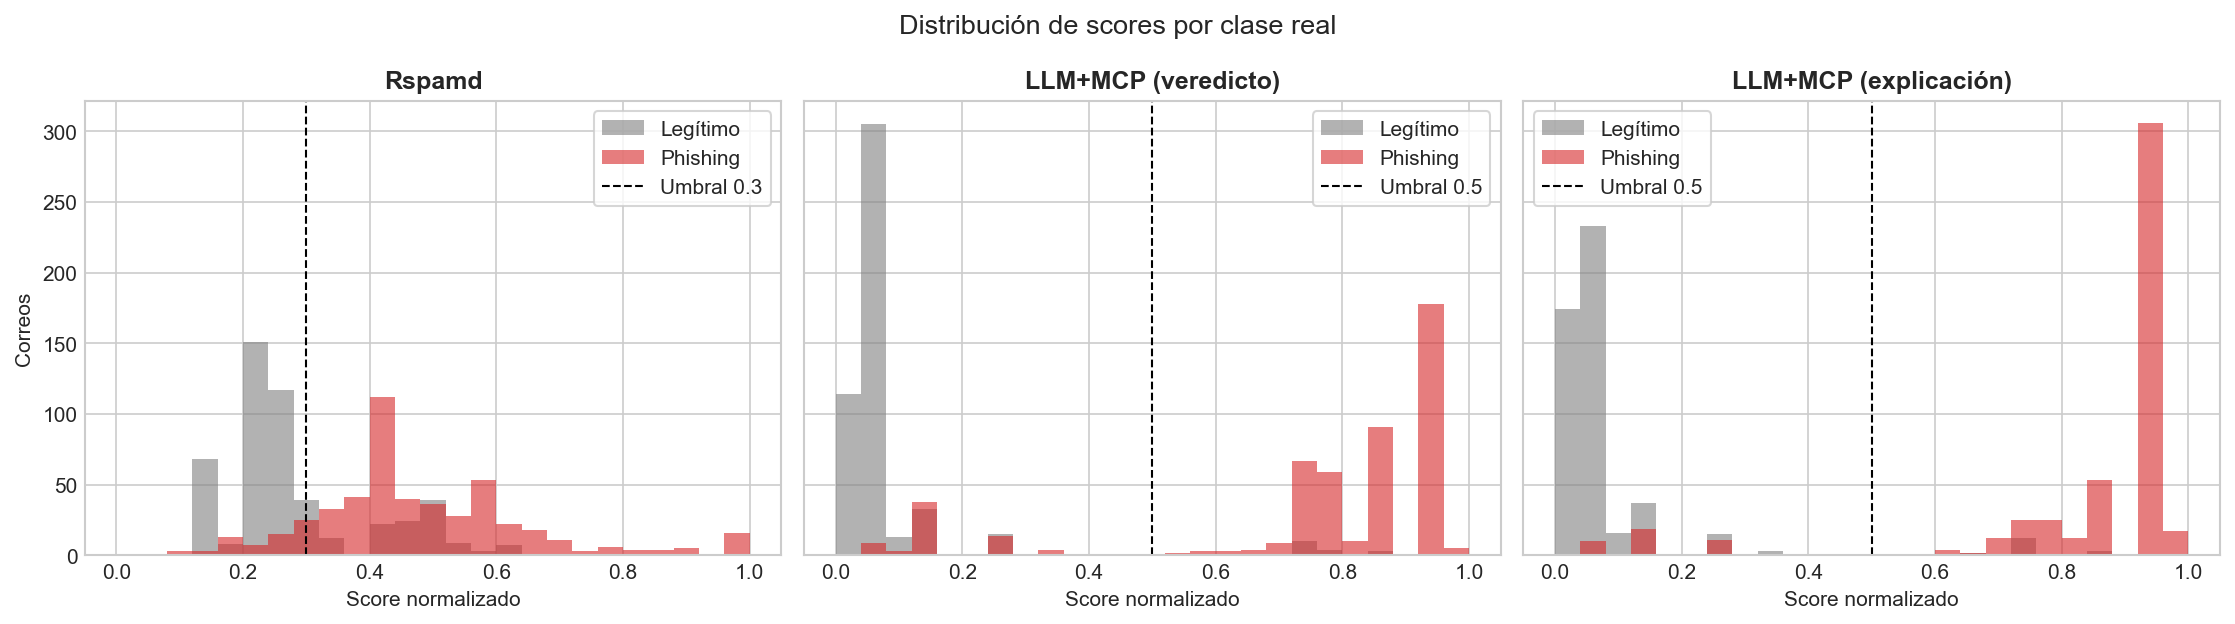

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
bins = np.linspace(0, 1, 26)

for ax, (sistema, info) in zip(axes, SISTEMAS.items()):
    validos = df[df[f"{sistema}_score"].notna()]
    for etiqueta, nombre, color in [(0, "Legítimo", "tab:gray"), (1, "Phishing", "tab:red")]:
        ax.hist(validos.loc[validos["label"] == etiqueta, f"{sistema}_score"], bins=bins, alpha=0.6, color=color, label=nombre)
    ax.axvline(UMBRALES[sistema], linestyle="--", color="black", linewidth=1, label=f"Umbral {UMBRALES[sistema]}")
    ax.set_title(info["nombre"], fontweight="bold")
    ax.set_xlabel("Score normalizado")
    ax.legend(frameon=True)

axes[0].set_ylabel("Correos")
fig.suptitle("Distribución de scores por clase real", fontsize=13)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "score_distributions_final.png")
plt.show()

## 8. Casos donde los sistemas difieren

Patrón de aciertos entre los tres sistemas, comparación par a par (prueba de McNemar exacta) y detalle de los
correos donde veredicto y explicación dan una clasificación distinta.

In [11]:
# Solo correos con resultado en los tres sistemas
completos = df[df[[f"{s}_pred" for s in SISTEMAS]].notna().all(axis=1)].copy()
for sistema in SISTEMAS:
    completos[f"{sistema}_ok"] = completos[f"{sistema}_pred"].astype(int) == completos["label"]

# Patrón de aciertos: qué combinación de sistemas clasifica bien cada correo
def patron(fila) -> str:
    bien = [SISTEMAS[s]["nombre"] for s in SISTEMAS if fila[f"{s}_ok"]]
    if len(bien) == len(SISTEMAS):
        return "Los tres aciertan"
    if not bien:
        return "Los tres fallan"
    return "Solo acierta(n): " + " + ".join(bien)


completos["patron"] = completos.apply(patron, axis=1)
clase = completos["label"].map({0: "Legítimos", 1: "Phishing"})
tabla_patron = pd.crosstab(completos["patron"], clase)
tabla_patron.columns.name = None
tabla_patron.insert(0, "Correos", tabla_patron.sum(axis=1))
tabla_patron.insert(1, "% del total", (tabla_patron["Correos"] / len(completos) * 100).round(1))
with pd.option_context("display.max_colwidth", None):
    display(tabla_patron.sort_values("Correos", ascending=False))

,Correos,% del total,Legítimos,Phishing
patron,,,,
Los tres aciertan,712,71.2,329,383
Solo acierta(n): LLM+MCP (veredicto) + LLM+MCP (explicación),188,18.8,140,48
Solo acierta(n): Rspamd,42,4.2,6,36
Solo acierta(n): Rspamd + LLM+MCP (explicación),26,2.6,5,21
Solo acierta(n): LLM+MCP (veredicto),10,1.0,9,1
Solo acierta(n): LLM+MCP (explicación),9,0.9,4,5
Los tres fallan,8,0.8,3,5
Solo acierta(n): Rspamd + LLM+MCP (veredicto),5,0.5,4,1


In [12]:
# Comparación par a par: correos donde solo acierta uno de los dos y prueba de McNemar exacta
pares = [("explicacion", "veredicto"), ("explicacion", "rspamd"), ("veredicto", "rspamd")]
filas = []
for a, b in pares:
    solo_a = int((completos[f"{a}_ok"] & ~completos[f"{b}_ok"]).sum())
    solo_b = int((~completos[f"{a}_ok"] & completos[f"{b}_ok"]).sum())
    p = binomtest(min(solo_a, solo_b), solo_a + solo_b, 0.5).pvalue if (solo_a + solo_b) else np.nan
    filas.append({
        "Par": f"{SISTEMAS[a]['nombre']} vs. {SISTEMAS[b]['nombre']}",
        "Clasificación distinta": int((completos[f"{a}_pred"] != completos[f"{b}_pred"]).sum()),
        "Solo acierta el primero": solo_a,
        "Solo acierta el segundo": solo_b,
        "Ambos fallan": int((~completos[f"{a}_ok"] & ~completos[f"{b}_ok"]).sum()),
        "McNemar p": p,
    })
pd.DataFrame(filas).set_index("Par").style.format({"McNemar p": "{:.2g}"})

,Clasificación distinta,Solo acierta el primero,Solo acierta el segundo,Ambos fallan,McNemar p
Par,,,,,
LLM+MCP (explicación) vs. LLM+MCP (veredicto),50,35,15,50,0.0066
LLM+MCP (explicación) vs. Rspamd,244,197,47,18,5e-23
LLM+MCP (veredicto) vs. Rspamd,266,198,68,17,6.6e-16


In [13]:
# McNemar por clase para explicación vs. veredicto: ¿la diferencia está en el phishing o en los legítimos?
filas = []
for etiqueta, nombre in [(1, "Phishing (recall)"), (0, "Legítimos (falsas alarmas)")]:
    sub = completos[completos["label"] == etiqueta]
    solo_e = int((sub["explicacion_ok"] & ~sub["veredicto_ok"]).sum())
    solo_v = int((~sub["explicacion_ok"] & sub["veredicto_ok"]).sum())
    filas.append({
        "Clase": nombre, "Correos": len(sub),
        "Solo acierta explicación": solo_e, "Solo acierta veredicto": solo_v,
        "Ambos fallan": int((~sub["explicacion_ok"] & ~sub["veredicto_ok"]).sum()),
        "McNemar p": binomtest(min(solo_e, solo_v), solo_e + solo_v, 0.5).pvalue if (solo_e + solo_v) else np.nan,
    })
pd.DataFrame(filas).set_index("Clase").style.format({"McNemar p": "{:.2g}"})

,Correos,Solo acierta explicación,Solo acierta veredicto,Ambos fallan,McNemar p
Clase,,,,,
Phishing (recall),500,26,2,41,3e-06
Legítimos (falsas alarmas),500,9,13,9,0.52


In [14]:
# Detalle: correos donde veredicto y explicación difieren en su clasificación
difieren = completos[completos["veredicto_pred"] != completos["explicacion_pred"]].copy()
difieren["acierta"] = np.where(difieren["veredicto_ok"], "veredicto", "explicación")
difieren["diferencia_score"] = (difieren["explicacion_score"] - difieren["veredicto_score"]).round(2)

print(f"Correos donde veredicto y explicación difieren: {len(difieren)} de {len(completos)}")
with pd.option_context("display.max_rows", 200):
    display(difieren.sort_values(["acierta", "label", "diferencia_score"])[
        ["id", "label", "arquetipo", "veredicto_score", "explicacion_score", "rspamd_pred", "acierta"]].reset_index(drop=True))

Correos donde veredicto y explicación difieren: 50 de 1000


,id,label,arquetipo,veredicto_score,explicacion_score,rspamd_pred,acierta
0,trec_2007_171,0,(sin arquetipo asignado),0.85,0.05,0,explicación
1,trec_2007_79,0,Suplantacion de boletin de noticias (alertas C...,0.76,0.15,1,explicación
2,trec_2007_233,0,Spam de acciones bursatiles 'pump and dump' (b...,0.72,0.15,0,explicación
3,trec_2007_384,0,Suplantacion de boletin de noticias (alertas C...,0.72,0.25,1,explicación
4,trec_2007_278,0,Spam de acciones bursatiles 'pump and dump' (b...,0.72,0.25,1,explicación
5,trec_2007_76,0,Suplantacion de boletin de noticias (alertas C...,0.72,0.25,1,explicación
6,trec_2007_18,0,Spam de acciones bursatiles 'pump and dump' (b...,0.72,0.25,0,explicación
7,trec_2007_122,0,Spam de acciones bursatiles 'pump and dump' (b...,0.72,0.25,0,explicación
8,trec_2007_157,0,Spam de acciones bursatiles 'pump and dump' (b...,0.42,0.15,0,explicación
9,phishing_pot_sample-1261,1,Spam de acciones bursatiles 'pump and dump' (b...,0.25,0.58,1,explicación


In [15]:
# Errores que comparten los dos modos del LLM: no dependen de los servidores MCP adicionales
compartidos = completos[~completos["veredicto_ok"] & ~completos["explicacion_ok"]]
print(f"Errores compartidos por veredicto y explicación: {len(compartidos)} "
      f"(phishing no detectado: {int((compartidos['label'] == 1).sum())}, "
      f"legítimos marcados: {int((compartidos['label'] == 0).sum())})")
print(f"De esos, Rspamd clasifica bien: {int(compartidos['rspamd_ok'].sum())}")

fn_todos = completos[(completos["label"] == 1) & ~completos[[f"{s}_ok" for s in SISTEMAS]].any(axis=1)]
print(f"Phishing que no detecta ninguno de los tres sistemas: {len(fn_todos)}")
compartidos.groupby(["label", "arquetipo"]).size().rename("Correos").sort_values(ascending=False).to_frame()

Errores compartidos por veredicto y explicación: 50 (phishing no detectado: 41, legítimos marcados: 9)
De esos, Rspamd clasifica bien: 42
Phishing que no detecta ninguno de los tres sistemas: 5


Correos
label arquetipo                                                  
1     Spam farmaceutico y de pastillas para adelgazar...       21
      Esquema de dinero facil y ganancias garantizada...        6
      Spam de acciones bursatiles 'pump and dump' (bo...        4
      Spam de atraccion y mejora sexual masculina con...        3
      Spam ofuscado de medicamentos genericos (evasio...        3
0     (sin arquetipo asignado)                                  2
      Spam de acciones bursatiles 'pump and dump' (bo...        2
      Spam farmaceutico y de pastillas para adelgazar...        2
1     Phishing de verificacion y suspension de cuenta           2
0     Spam de hipotecas y prestamos preaprobados                1
      Suplantacion de boletin de noticias (alertas CN...        1
      Venta de software pirata a precio muy bajo                1
1     Spam ofuscado de agrandamiento masculino con ps...        1
      Venta de software pirata a precio muy bajo                1

## 9. Falsos negativos por arquetipo

Phishing no detectado por cada sistema, agrupado por el arquetipo que asignó el servidor archetype en el modo
veredicto. Permite ver en qué tipo de correo gana detección el modo explicación.

,phishing,FN_rspamd,FN_veredicto,FN_explicacion,recuperados_por_explicacion,perdidos_por_explicacion
arquetipo,,,,,,
Spam farmaceutico y de pastillas para adelgazar con frases de marketing concatenadas (evasion de filtros),182,25,38,22,17,1
Spam de acciones bursatiles 'pump and dump' (boletines de inversion falsos),18,2,7,5,3,1
Esquema de dinero facil y ganancias garantizadas (estilo loteria/MLM),39,6,6,6,0,0
Spam ofuscado de medicamentos genericos (evasion de filtros),8,3,6,3,3,0
Phishing de verificacion y suspension de cuenta,161,18,4,2,2,0
Spam de atraccion y mejora sexual masculina con tono agresivo y pseudo-respaldo de 'estudios',15,1,4,3,1,0
Spam ofuscado de agrandamiento masculino con pseudo-respaldo medico (evasion de filtros),6,1,1,1,0,0
Venta de software pirata a precio muy bajo,2,2,1,1,0,0
(sin arquetipo asignado),43,1,0,0,0,0


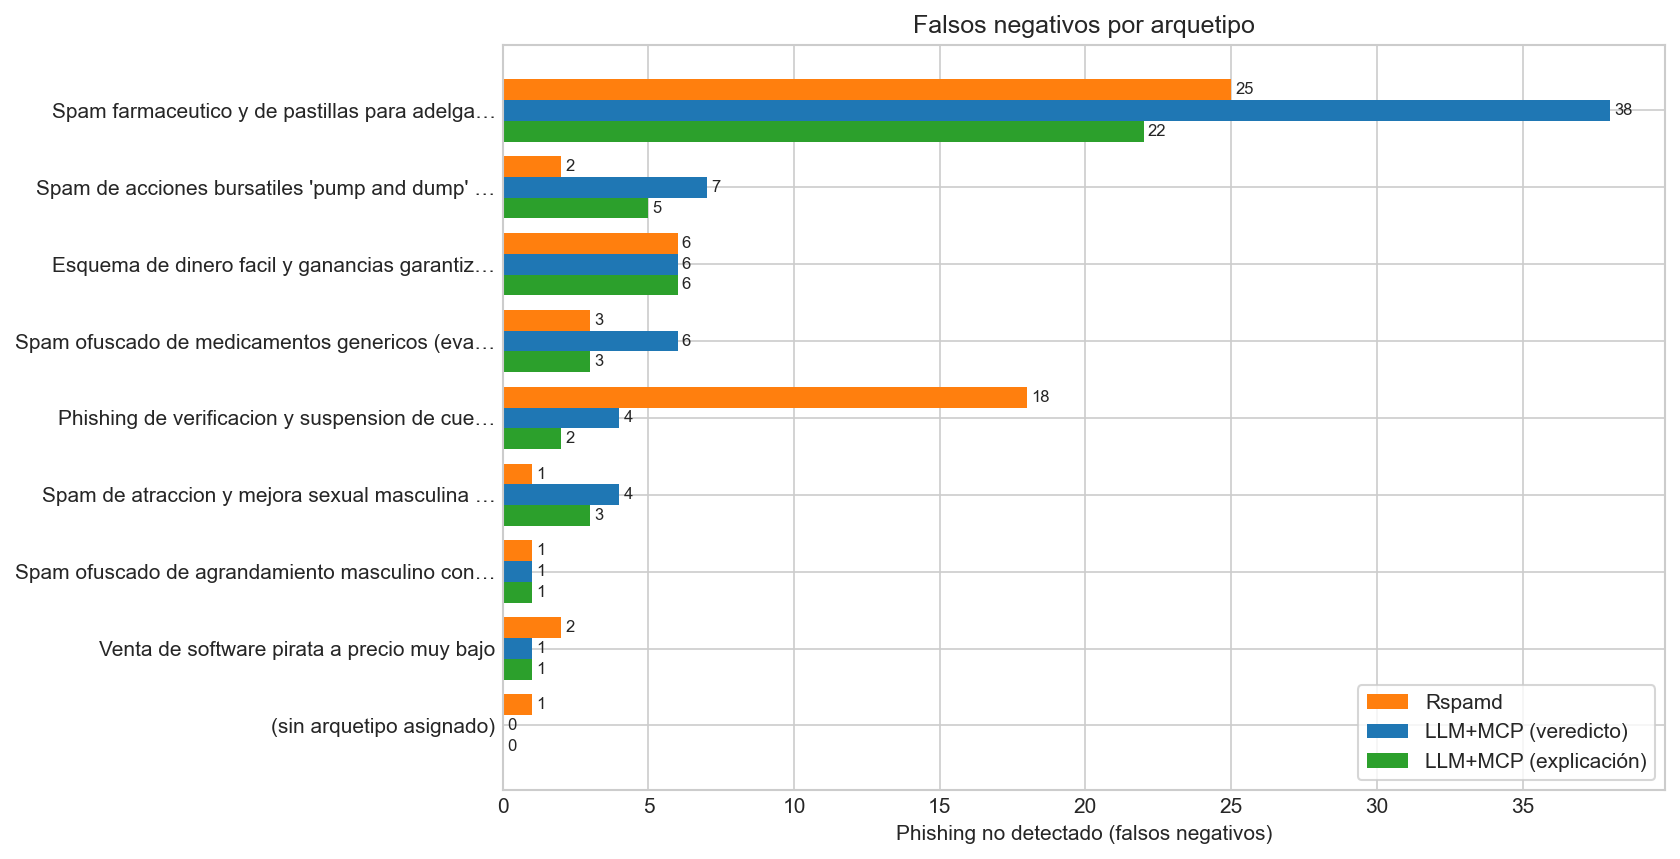

In [16]:
phishing = completos[completos["label"] == 1]
por_arquetipo = phishing.groupby("arquetipo").agg(
    phishing=("id", "count"),
    FN_rspamd=("rspamd_ok", lambda s: int((~s).sum())),
    FN_veredicto=("veredicto_ok", lambda s: int((~s).sum())),
    FN_explicacion=("explicacion_ok", lambda s: int((~s).sum())),
)
por_arquetipo["recuperados_por_explicacion"] = phishing[~phishing["veredicto_ok"] & phishing["explicacion_ok"]].groupby("arquetipo").size()
por_arquetipo["perdidos_por_explicacion"] = phishing[phishing["veredicto_ok"] & ~phishing["explicacion_ok"]].groupby("arquetipo").size()
por_arquetipo = por_arquetipo.fillna(0).astype(int).sort_values("FN_veredicto", ascending=False)
with pd.option_context("display.max_colwidth", None):
    display(por_arquetipo)

top = por_arquetipo[(por_arquetipo[["FN_rspamd", "FN_veredicto", "FN_explicacion"]].sum(axis=1) > 0)].head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(10, 0.55 * len(top) + 1.5))
pos = np.arange(len(top))
alto = 0.27
for k, (sistema, info) in enumerate(SISTEMAS.items()):
    barras = ax.barh(pos + (1 - k) * alto, top[f"FN_{sistema}"], alto, color=info["color"], label=info["nombre"])
    ax.bar_label(barras, padding=2, fontsize=8)
ax.set_yticks(pos)
ax.set_yticklabels([t if len(t) <= 45 else t[:44] + "…" for t in top.index])
ax.set_xlabel("Phishing no detectado (falsos negativos)")
ax.set_title("Falsos negativos por arquetipo")
ax.legend(frameon=True, loc="lower right")
fig.savefig(FIGURES_DIR / "fn_por_arquetipo_final.png")
plt.show()

## 10. Comparación visual de los tres sistemas

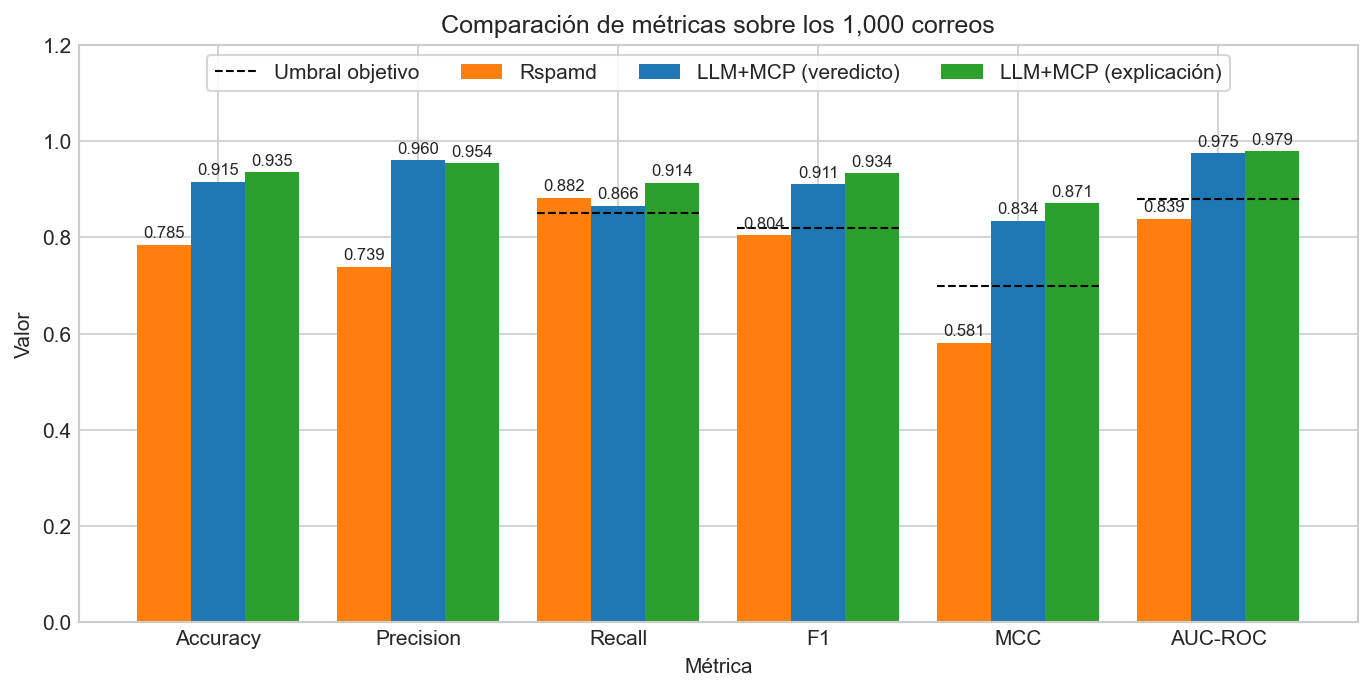

In [17]:
# Barras agrupadas con las métricas principales
x = np.arange(len(METRICAS))
ancho = 0.27

fig, ax = plt.subplots(figsize=(11, 5))
for k, (sistema, info) in enumerate(SISTEMAS.items()):
    barras = ax.bar(x + (k - 1) * ancho, tabla_metricas.loc[info["nombre"], METRICAS].astype(float), ancho,
                    color=info["color"], label=info["nombre"])
    ax.bar_label(barras, fmt="%.3f", padding=2, fontsize=8)

# Marca del umbral objetivo en las métricas que lo tienen
for m, objetivo in OBJETIVOS.items():
    i = METRICAS.index(m)
    ax.hlines(objetivo, i - 1.5 * ancho, i + 1.5 * ancho, colors="black", linestyles="--", linewidth=1,
              label="Umbral objetivo" if m == "Recall" else None)

ax.set_xticks(x)
ax.set_xticklabels(METRICAS)
ax.set_ylim(0, 1.2)
ax.set_xlabel("Métrica")
ax.set_ylabel("Valor")
ax.set_title("Comparación de métricas sobre los 1,000 correos")
ax.legend(loc="upper center", ncol=4, frameon=True)
fig.savefig(FIGURES_DIR / "metrics_comparison_final.png")
plt.show()

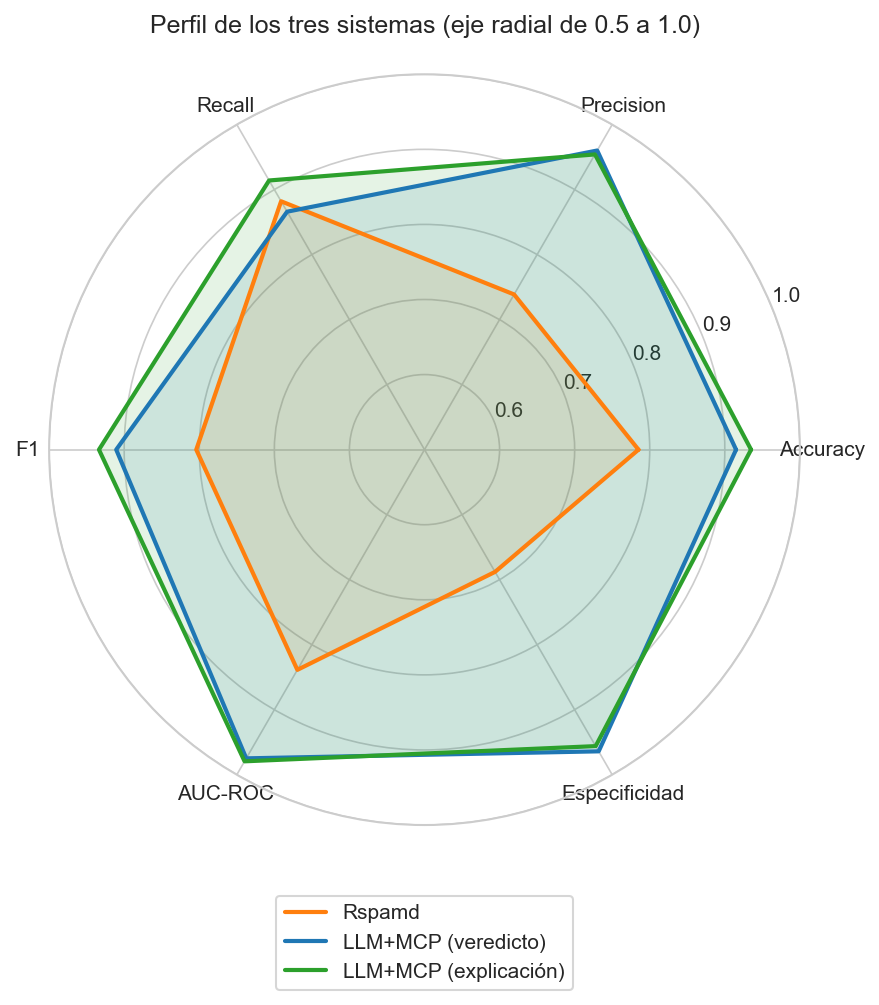

In [18]:
# Gráfico de radar: mismas métricas, más la especificidad (1 - FPR) para que "más afuera" sea siempre mejor
ejes = ["Accuracy", "Precision", "Recall", "F1", "AUC-ROC", "Especificidad"]
radar = tabla_metricas[["Accuracy", "Precision", "Recall", "F1", "AUC-ROC"]].astype(float).copy()
radar["Especificidad"] = 1 - tabla_metricas["FPR"].astype(float)

angulos = np.linspace(0, 2 * np.pi, len(ejes), endpoint=False).tolist()
angulos += angulos[:1]

fig, ax = plt.subplots(figsize=(6.5, 6.5), subplot_kw={"polar": True})
for sistema, info in SISTEMAS.items():
    valores = radar.loc[info["nombre"], ejes].tolist()
    valores += valores[:1]
    ax.plot(angulos, valores, color=info["color"], linewidth=2, label=info["nombre"])
    ax.fill(angulos, valores, color=info["color"], alpha=0.12)

ax.set_xticks(angulos[:-1])
ax.set_xticklabels(ejes)
ax.set_ylim(0.5, 1.0)
ax.set_yticks([0.6, 0.7, 0.8, 0.9, 1.0])
ax.set_title("Perfil de los tres sistemas (eje radial de 0.5 a 1.0)", pad=20)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=1, frameon=True)
fig.savefig(FIGURES_DIR / "radar_final.png")
plt.show()

## 11. Modo explicación: señales y uso de los servidores MCP

Qué servidores consultó el orquestador, cuántas señales aportó cada uno y cómo se comportó VirusTotal.

In [19]:
SERVIDORES = ["archetype", "knowledge", "coherence", "virustotal"]
con_explicacion = df[df["herramientas_invocadas"].notna()]

# Llamadas a herramientas por servidor
llamadas = pd.DataFrame(
    [{"id": fila.id, "servidor": h.get("servidor"), "ok": bool(h.get("ok")), "error": h.get("error")}
     for fila in con_explicacion.itertuples() for h in fila.herramientas_invocadas]
)
llamadas["servidor"] = llamadas["servidor"].where(llamadas["servidor"].isin(SERVIDORES), "otro")
# Señales reportadas por servidor
senales = pd.DataFrame(
    [{"id": fila.id, "label": fila.label, "servidor": str(s.get("servidor", "")).lower()}
     for fila in con_explicacion.itertuples() for s in fila.senales]
)
senales["servidor"] = senales["servidor"].where(senales["servidor"].isin(SERVIDORES), "otro")

uso = pd.DataFrame({
    "Llamadas": llamadas.groupby("servidor").size(),
    "Llamadas fallidas": llamadas[~llamadas["ok"]].groupby("servidor").size(),
    "Correos en que se consultó": llamadas.groupby("servidor")["id"].nunique(),
    "Señales reportadas": senales.groupby("servidor").size(),
    "Señales por correo, phishing": senales[senales["label"] == 1].groupby("servidor").size() / (con_explicacion["label"] == 1).sum(),
    "Señales por correo, legítimo": senales[senales["label"] == 0].groupby("servidor").size() / (con_explicacion["label"] == 0).sum(),
}).reindex(SERVIDORES + ["otro"]).fillna(0)
uso.style.format("{:.0f}").format("{:.2f}", subset=["Señales por correo, phishing", "Señales por correo, legítimo"])

,Llamadas,Llamadas fallidas,Correos en que se consultó,Señales reportadas,"Señales por correo, phishing","Señales por correo, legítimo"
servidor,,,,,,
archetype,1467,15,999,1038,1.07,1.00
knowledge,2332,72,934,1295,1.65,0.94
coherence,1053,24,999,2469,3.54,1.39
virustotal,2550,197,761,1520,1.13,1.91
otro,5,5,5,5,0.01,0.00


In [20]:
# VirusTotal: por qué fallaron las consultas fallidas
CLAVES_CUOTA = ("quota", "rate limit", "too many requests", "daily", "exceeded", "limit")

def motivo(error) -> str:
    e = str(error or "").lower()
    if any(c in e for c in CLAVES_CUOTA):
        return "Cuota agotada"
    if "did not complete" in e or "timed out" in e:
        return "Análisis no terminó a tiempo"
    if "not a valid" in e or "validation failed" in e:
        return "Dominio, URL o IP inválidos"
    if "not found" in e:
        return "No encontrado en VirusTotal"
    if "not authorized" in e:
        return "Operación no permitida en el plan gratuito"
    return "Otro (conexión, etc.)"

vt = llamadas[llamadas["servidor"] == "virustotal"]
print(f"Consultas a VirusTotal: {len(vt)} | fallidas: {int((~vt['ok']).sum())} ({(~vt['ok']).mean():.1%}) | "
      f"correos con al menos una consulta: {vt['id'].nunique()}")
vt.loc[~vt["ok"], "error"].map(motivo).value_counts().rename("Consultas fallidas").to_frame()

Consultas a VirusTotal: 2550 | fallidas: 197 (7.7%) | correos con al menos una consulta: 761


,Consultas fallidas
error,
"Dominio, URL o IP inválidos",130
Análisis no terminó a tiempo,31
Operación no permitida en el plan gratuito,20
"Otro (conexión, etc.)",9
No encontrado en VirusTotal,7


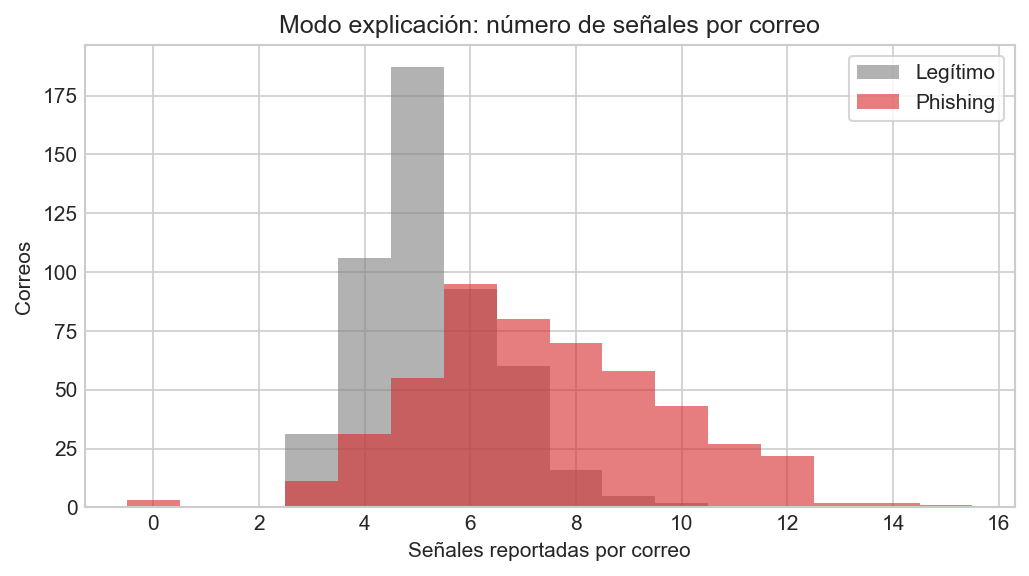

,Tiempo mediano por correo (s),Tiempo medio por correo (s),Tiempo total (h),Costo total (USD)
Rspamd,0.26,0.34,0.09,0 (self-hosted)
LLM+MCP (veredicto),22.11,27.64,7.68,21.87
LLM+MCP (explicación),58.38,75.20,20.89,no registrado


In [21]:
# Señales por correo según la clase real, y tiempos y costo de cada sistema
fig, ax = plt.subplots(figsize=(8, 4))
maximo = int(con_explicacion["senales_count"].max())
for etiqueta, nombre, color in [(0, "Legítimo", "tab:gray"), (1, "Phishing", "tab:red")]:
    ax.hist(con_explicacion.loc[con_explicacion["label"] == etiqueta, "senales_count"], bins=np.arange(-0.5, maximo + 1.5),
            alpha=0.6, color=color, label=nombre)
ax.set_xlabel("Señales reportadas por correo")
ax.set_ylabel("Correos")
ax.set_title("Modo explicación: número de señales por correo")
ax.legend(frameon=True)
fig.savefig(FIGURES_DIR / "senales_por_correo_final.png")
plt.show()

operativo = pd.DataFrame({
    info["nombre"]: {
        "Tiempo mediano por correo (s)": df[f"{s}_tiempo_ms"].median() / 1000,
        "Tiempo medio por correo (s)": df[f"{s}_tiempo_ms"].mean() / 1000,
        "Tiempo total (h)": df[f"{s}_tiempo_ms"].sum() / 3.6e6,
    } for s, info in SISTEMAS.items()
}).T.round(2)
operativo["Costo total (USD)"] = ["0 (self-hosted)", f"{df['veredicto_costo_usd'].sum():.2f}", "no registrado"]
operativo

## 12. Resumen para el capítulo de resultados

> Cifras de las corridas terminadas el 2026-10-10. Si se regenera algún archivo de resultados, actualizar estas tablas con las de las secciones 3, 8 y 9.

**Tabla. Desempeño de los tres sistemas sobre 1,000 correos (500 phishing, 500 legítimos).**

| Sistema | Accuracy | Precision | Recall | F1 | MCC | AUC-ROC | FP | FN |
|---|---|---|---|---|---|---|---|---|
| Rspamd (umbral 6.0) | 0.785 | 0.739 | 0.882 | 0.804 | 0.581 | 0.839 | 156 | 59 |
| LLM+MCP, modo veredicto | 0.915 | **0.960** | 0.866 | 0.911 | 0.834 | 0.975 | **18** | 67 |
| LLM+MCP, modo explicación | **0.935** | 0.954 | **0.914** | **0.934** | **0.871** | **0.979** | 22 | **43** |

**Tabla. Explicación frente a veredicto, por clase (McNemar exacta).**

| Clase | Solo acierta explicación | Solo acierta veredicto | Ambos fallan | p |
|---|---|---|---|---|
| Phishing (500) | 26 | 2 | 41 | < 0.001 |
| Legítimos (500) | 9 | 13 | 9 | 0.52 |
| Total (1,000) | 35 | 15 | 50 | 0.007 |

**Lectura.**

- **Los dos modos del sistema LLM+MCP cumplen los cuatro umbrales objetivo de la tesis** (Recall ≥ 0.85,
  F1 ≥ 0.82, AUC-ROC ≥ 0.88, MCC ≥ 0.70). Rspamd solo cumple el de Recall.
- **Ambos modos superan a Rspamd de forma significativa** (McNemar, p < 0.001). La mayor diferencia está en las
  falsas alarmas: Rspamd marca como phishing 156 de los 500 legítimos (31.2 %), frente a 18 (3.6 %) y 22 (4.4 %).
- **El modo explicación detecta más phishing que el modo veredicto, y la diferencia es significativa.** El
  Recall sube de 0.866 a 0.914: 24 phishing menos sin detectar (de 67 a 43). Recupera 26 phishing que el
  veredicto dejaba pasar y pierde 2. En los legítimos no hay diferencia significativa (22 frente a 18 falsos
  positivos, p = 0.52), así que la mejora en detección no se paga con más falsas alarmas de forma demostrable.
- **Con 1,000 correos cambia la conclusión de las submuestras.** Con 100 y 200 correos los dos modos eran
  indistinguibles (discrepaban en 4 correos); con 1,000 discrepan en 50 y la ventaja del modo explicación en
  Recall queda fuera del margen de error. La muestra pequeña no tenía potencia para verlo.
- **La mejora se concentra en el spam comercial, que era el punto débil del modo veredicto.** En el arquetipo
  de spam farmacéutico los falsos negativos bajan de 38 a 22, en medicamentos genéricos ofuscados de 6 a 3 y
  en acciones bursátiles de 7 a 5. En el phishing de verificación y suspensión de cuenta ambos modos ya eran
  fuertes (4 y 2 falsos negativos de 161, frente a 18 de Rspamd).
- **El modo explicación supera también a Rspamd en detección** (Recall 0.914 frente a 0.882), cosa que el modo
  veredicto no lograba (0.866).
- **Los sistemas siguen siendo complementarios.** Los dos modos del LLM comparten 50 errores (41 phishing no
  detectados y 9 legítimos marcados) y Rspamd clasifica bien 42 de ellos. Solo 5 phishing de 500 no los
  detecta ninguno de los tres sistemas.
- **Qué aporta cada servidor MCP.** El servidor de coherencia es el que más discrimina: reporta 3.5 señales
  por correo de phishing frente a 1.4 en los legítimos. VirusTotal se consultó en 761 correos y falló en el
  7.7 % de sus 2,550 consultas, ninguna por cuota agotada.
- **Costo.** El modo explicación tarda una mediana de 58 s por correo frente a 22 s del modo veredicto (20.9 h
  frente a 7.7 h para los 1,000). El modo veredicto costó USD 21.87; el costo del modo explicación no quedó
  registrado.

**Limitaciones a declarar.** (1) El sistema LLM recibió solo el cuerpo del correo (`body`), mientras que
Rspamd recibió el correo con encabezados (`raw_text`). (2) Los legítimos de TREC tienen encabezados
reconstruidos, lo que probablemente infla los falsos positivos de Rspamd. (3) Cada modo se corrió una sola vez
(temperatura 0) y en fechas distintas: el modo veredicto en septiembre y el modo explicación entre el 4 y el
10 de octubre, en varias tandas por la cuota diaria de VirusTotal. (4) En el modo veredicto hay 3 correos cuya
clasificación emitida no coincide con el umbral de 0.5 sobre su puntaje; se usó la clasificación emitida. Con
el umbral, el modo veredicto tendría TP 431, FP 17, FN 69 (F1 0.909). (5) El costo en tokens del modo
explicación no quedó registrado. (6) Buena parte del "phishing" de Phishing Pot es spam comercial, y algunos
correos de TREC etiquetados como legítimos parecen spam; eso afecta a los tres sistemas.